# Bài thực hành Buổi 1 - Bài 2 Trang 37-38
## Online Retail - United Kingdom

In [1]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid")


Ngô Thành Khôi - 6451071038


### Câu 1-3: Đọc và làm sạch dữ liệu

In [2]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Đọc dữ liệu và tiền xử lý
retail = pd.read_excel("Online Retail.xlsx")
retail["Description"] = retail["Description"].astype("string").str.strip()
retail = retail.dropna(subset=["InvoiceNo"]).copy()
retail["InvoiceNo"] = retail["InvoiceNo"].astype(str)
retail = retail[~retail["InvoiceNo"].str.contains("C", na=False)].copy()
print("Số dòng sau tiền xử lý:", len(retail))
display(retail.head())


Ngô Thành Khôi - 6451071038
Số dòng sau tiền xử lý: 532621


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### Câu 4: Thống kê số dòng theo quốc gia

Ngô Thành Khôi - 6451071038


Country
United Kingdom          487622
Germany                   9042
France                    8408
EIRE                      7894
Spain                     2485
Netherlands               2363
Belgium                   2031
Switzerland               1967
Portugal                  1501
Australia                 1185
Norway                    1072
Italy                      758
Channel Islands            748
Finland                    685
Cyprus                     614
Sweden                     451
Unspecified                446
Austria                    398
Denmark                    380
Poland                     330
Japan                      321
Israel                     295
Hong Kong                  284
Singapore                  222
Iceland                    182
USA                        179
Canada                     151
Greece                     145
Malta                      112
United Arab Emirates        68
European Community          60
RSA                         58


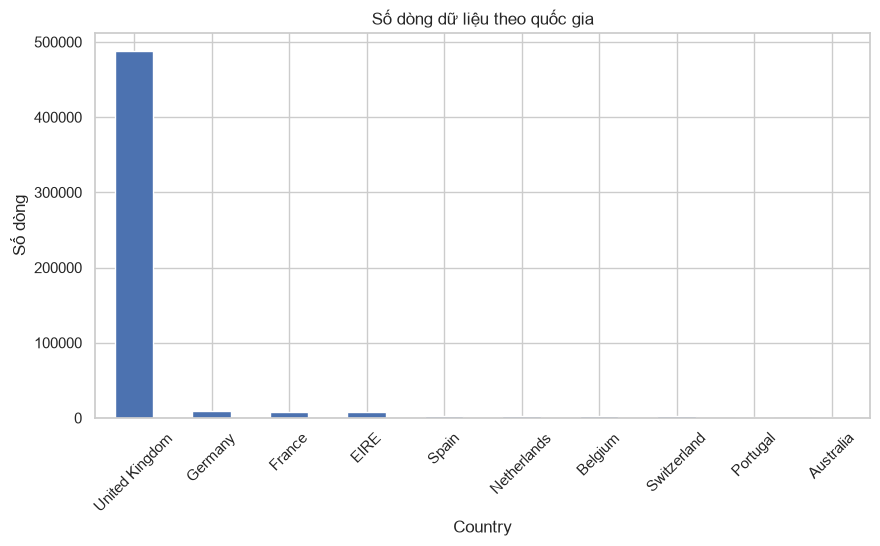

In [3]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Thống kê số dòng dữ liệu theo Country
country_counts = retail["Country"].value_counts()
display(country_counts)
country_counts.head(10).plot(kind="bar", figsize=(10, 5))
plt.title("Số dòng dữ liệu theo quốc gia")
plt.ylabel("Số dòng")
plt.xticks(rotation=45)
plt.show()


### Câu 5-8: Lọc United Kingdom, gom nhóm và tạo one-hot encoding

In [4]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Lọc United Kingdom
uk = retail[retail["Country"] == "United Kingdom"].copy()

# Gom Quantity theo InvoiceNo và Description
basket = uk.groupby(["InvoiceNo", "Description"])["Quantity"].sum().unstack().fillna(0)

# Chuyển thành one-hot encoding
basket_encoded = basket.map(lambda value: 1 if value >= 1 else 0)
basket_encoded = basket_encoded.drop(columns=["POSTAGE"], errors="ignore")

print("Kích thước ma trận:", basket_encoded.shape)
display(basket_encoded.head())


Ngô Thành Khôi - 6451071038
Kích thước ma trận: (18668, 4175)


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,wrongly coded 20713,wrongly coded 23343,wrongly coded-23343,wrongly marked,wrongly marked 23343,wrongly marked carton 22804,wrongly marked. 23343 in box,wrongly sold (22719) barcode,wrongly sold as sets,wrongly sold sets
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536366,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536367,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536368,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536369,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Câu 9-10: Tìm tập phổ biến và sinh luật bằng Apriori

In [5]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Apriori và association_rules
uk_apriori_items = apriori(basket_encoded, min_support=0.03, use_colnames=True)
uk_apriori_rules = association_rules(uk_apriori_items, metric="confidence", min_threshold=0.5)
uk_apriori_rules = uk_apriori_rules.sort_values(["confidence", "lift"], ascending=False)

print("Số tập phổ biến:", len(uk_apriori_items))
for _, row in uk_apriori_rules.iterrows():
    print(f"{set(row['antecedents'])} ==> {set(row['consequents'])} [ {row['support']:.4f} , {row['confidence']:.4f} ]")


Ngô Thành Khôi - 6451071038


c:\Users\Thanh Khoi\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


Số tập phổ biến: 131
{'PINK REGENCY TEACUP AND SAUCER'} ==> {'GREEN REGENCY TEACUP AND SAUCER'} [ 0.0309 , 0.8208 ]
{'GREEN REGENCY TEACUP AND SAUCER'} ==> {'ROSES REGENCY TEACUP AND SAUCER'} [ 0.0376 , 0.7505 ]
{'ROSES REGENCY TEACUP AND SAUCER'} ==> {'GREEN REGENCY TEACUP AND SAUCER'} [ 0.0376 , 0.7325 ]
{'JUMBO BAG PINK POLKADOT'} ==> {'JUMBO BAG RED RETROSPOT'} [ 0.0421 , 0.6773 ]
{'ALARM CLOCK BAKELIKE GREEN'} ==> {'ALARM CLOCK BAKELIKE RED'} [ 0.0302 , 0.6427 ]
{'JUMBO  BAG BAROQUE BLACK WHITE'} ==> {'JUMBO BAG RED RETROSPOT'} [ 0.0305 , 0.6264 ]
{'GREEN REGENCY TEACUP AND SAUCER'} ==> {'PINK REGENCY TEACUP AND SAUCER'} [ 0.0309 , 0.6178 ]
{'JUMBO STORAGE BAG SUKI'} ==> {'JUMBO BAG RED RETROSPOT'} [ 0.0374 , 0.6177 ]
{'ALARM CLOCK BAKELIKE RED'} ==> {'ALARM CLOCK BAKELIKE GREEN'} [ 0.0302 , 0.6054 ]
{'JUMBO SHOPPER VINTAGE RED PAISLEY'} ==> {'JUMBO BAG RED RETROSPOT'} [ 0.0352 , 0.5799 ]


### Câu 11: Scatter plot support và confidence

Ngô Thành Khôi - 6451071038


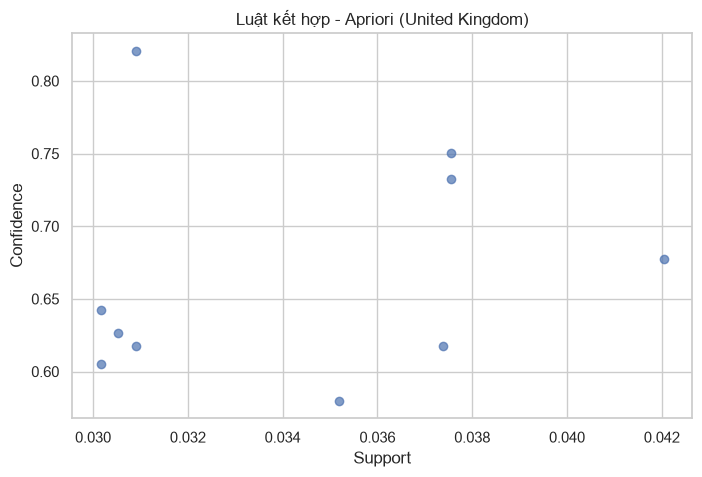

In [6]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Vẽ support vs confidence cho các luật Apriori
plt.figure(figsize=(8, 5))
plt.scatter(uk_apriori_rules["support"], uk_apriori_rules["confidence"], alpha=0.7)
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Luật kết hợp - Apriori (United Kingdom)")
plt.grid(True)
plt.show()


### Câu 12: FP-Growth và so sánh với Apriori

In [7]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# FP-Growth với cùng ngưỡng
uk_fp_items = fpgrowth(basket_encoded, min_support=0.03, use_colnames=True)
uk_fp_rules = association_rules(uk_fp_items, metric="confidence", min_threshold=0.5)
uk_fp_rules = uk_fp_rules.sort_values(["confidence", "lift"], ascending=False)

print("FP-Growth - tập phổ biến:")
display(uk_fp_items.head())
print("FP-Growth - luật kết hợp:")
for _, row in uk_fp_rules.iterrows():
    print(f"{set(row['antecedents'])} ==> {set(row['consequents'])} [ {row['support']:.4f} , {row['confidence']:.4f} ]")


Ngô Thành Khôi - 6451071038


c:\Users\Thanh Khoi\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


FP-Growth - tập phổ biến:


,support,itemsets
0,0.116027,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
1,0.073441,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
2,0.040069,frozenset({HOME BUILDING BLOCK WORD})
3,0.032516,frozenset({LOVE BUILDING BLOCK WORD})
4,0.030105,frozenset({DOORMAT NEW ENGLAND})


FP-Growth - luật kết hợp:
{'PINK REGENCY TEACUP AND SAUCER'} ==> {'GREEN REGENCY TEACUP AND SAUCER'} [ 0.0309 , 0.8208 ]
{'GREEN REGENCY TEACUP AND SAUCER'} ==> {'ROSES REGENCY TEACUP AND SAUCER'} [ 0.0376 , 0.7505 ]
{'ROSES REGENCY TEACUP AND SAUCER'} ==> {'GREEN REGENCY TEACUP AND SAUCER'} [ 0.0376 , 0.7325 ]
{'JUMBO BAG PINK POLKADOT'} ==> {'JUMBO BAG RED RETROSPOT'} [ 0.0421 , 0.6773 ]
{'ALARM CLOCK BAKELIKE GREEN'} ==> {'ALARM CLOCK BAKELIKE RED'} [ 0.0302 , 0.6427 ]
{'JUMBO  BAG BAROQUE BLACK WHITE'} ==> {'JUMBO BAG RED RETROSPOT'} [ 0.0305 , 0.6264 ]
{'GREEN REGENCY TEACUP AND SAUCER'} ==> {'PINK REGENCY TEACUP AND SAUCER'} [ 0.0309 , 0.6178 ]
{'JUMBO STORAGE BAG SUKI'} ==> {'JUMBO BAG RED RETROSPOT'} [ 0.0374 , 0.6177 ]
{'ALARM CLOCK BAKELIKE RED'} ==> {'ALARM CLOCK BAKELIKE GREEN'} [ 0.0302 , 0.6054 ]
{'JUMBO SHOPPER VINTAGE RED PAISLEY'} ==> {'JUMBO BAG RED RETROSPOT'} [ 0.0352 , 0.5799 ]


**Nhận xét so sánh:** Apriori và FP-Growth tìm cùng tập phổ biến và các luật khi dùng cùng dữ liệu/ngưỡng; kết quả tương đương, nhưng FP-Growth thường hiệu quả hơn với dữ liệu dày và ngưỡng support thấp nhờ cấu trúc FP-tree.